# Experiment 4: Hypothesis Testing

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.power import TTestIndPower

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
alpha = 0.05
results = []

## Load datasets

In [2]:
penguins = sns.load_dataset("penguins").dropna()
tips = sns.load_dataset("tips")
print(penguins.shape, tips.shape)
penguins.head()

(333, 7) (244, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


## Normality test (assumption check)

In [3]:
adelie = penguins[penguins["species"] == "Adelie"]
W, p = stats.shapiro(adelie["flipper_length_mm"])
print(f"Shapiro-Wilk: W = {W:.4f}, p = {p:.4f}")
print("Normal at 5%?", p > alpha)

Shapiro-Wilk: W = 0.9934, p = 0.7427
Normal at 5%? True


## One-sample t-test

In [4]:
# H0: mean flipper length of Adelie penguins = 190 mm; H1: mean != 190 mm
sample = adelie["flipper_length_mm"]
t, p = stats.ttest_1samp(sample, popmean=190)
print(f"n = {len(sample)}, sample mean = {sample.mean():.3f}")
print(f"t = {t:.4f}, p = {p:.6f}")
display(results.append(["One-sample t-test", t, p]))

ci = stats.t.interval(0.95, df=len(sample) - 1, loc=sample.mean(), scale=stats.sem(sample))
print("95% CI for the mean:", np.round(ci, 3))

n = 146, sample mean = 190.103
t = 0.1903, p = 0.849304


None

95% CI for the mean: [189.036 191.17 ]


## One-sample z-test

In [5]:
# H0: mean total bill = 20; H1: mean total bill != 20
z, p = ztest(tips["total_bill"], value=20)
print(f"n = {len(tips)}, sample mean = {tips['total_bill'].mean():.3f}")
print(f"z = {z:.4f}, p = {p:.6f}")
results.append(["One-sample z-test", z, p])

n = 244, sample mean = 19.786
z = -0.3756, p = 0.707220


## Independent two-sample t-test

Levene test for equal variances: LeveneResult(statistic=np.float64(0.5753656851309165), pvalue=np.float64(0.4496598843143381))
Shapiro male: 0.985 | Shapiro female: 0.5107
Student t-test: t = 14.7217, p = 2.134e-28
Welch t-test:   t = 14.7614, p = 1.868e-28


None

Cohen's d: 2.6999


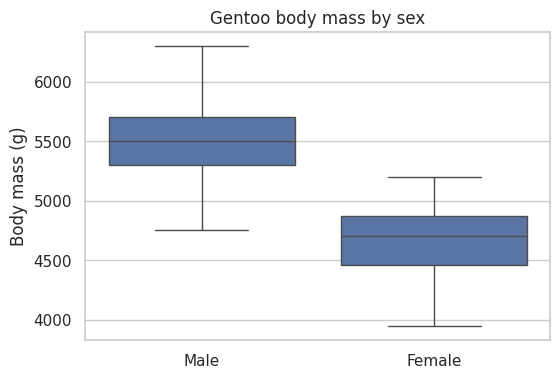

In [6]:
gentoo = penguins[penguins["species"] == "Gentoo"]
male = gentoo.loc[gentoo["sex"] == "Male", "body_mass_g"]
female = gentoo.loc[gentoo["sex"] == "Female", "body_mass_g"]
print("Levene test for equal variances:", stats.levene(male, female))
print("Shapiro male:", stats.shapiro(male)[1].round(4), "| Shapiro female:", stats.shapiro(female)[1].round(4))

t, p = stats.ttest_ind(male, female, equal_var=True)
print(f"Student t-test: t = {t:.4f}, p = {p:.3e}")
t_w, p_w = stats.ttest_ind(male, female, equal_var=False)
print(f"Welch t-test:   t = {t_w:.4f}, p = {p_w:.3e}")
display(results.append(["Two-sample t-test (Gentoo male vs female mass)", t, p]))

pooled = np.sqrt(((len(male) - 1) * male.var() + (len(female) - 1) * female.var()) / (len(male) + len(female) - 2))
cohen_d = (male.mean() - female.mean()) / pooled
print("Cohen's d:", round(cohen_d, 4))

plt.figure(figsize=(6, 4))
sns.boxplot(x=[*["Male"] * len(male), *["Female"] * len(female)], y=np.concatenate([male, female]))
plt.ylabel("Body mass (g)"); plt.title("Gentoo body mass by sex")
plt.show()

## One-tailed test

In [7]:
# H0: mean(male) <= mean(female); H1: mean(male) > mean(female)
t, p = stats.ttest_ind(male, female, alternative="greater")
print(f"t = {t:.4f}, one-tailed p = {p:.3e}")
results.append(["One-tailed t-test (male > female)", t, p])

t = 14.7217, one-tailed p = 1.067e-28


## Paired t-test

In [8]:
before = rng.normal(loc=75, scale=8, size=30)
after = before - rng.normal(loc=3, scale=4, size=30)
pairs = pd.DataFrame({"before": before, "after": after})
display(pairs.describe().round(3))

t, p = stats.ttest_rel(pairs["before"], pairs["after"])
print(f"t = {t:.4f}, p = {p:.6f}")
print("Mean difference:", (pairs["before"] - pairs["after"]).mean().round(3))
results.append(["Paired t-test", t, p])

,before,after
count,30.000,30.000
mean,75.135,71.679
std,6.214,7.391
min,59.392,53.928
25%,71.726,66.639
50%,75.775,71.890
75%,79.129,76.059
max,84.780,87.609


t = 5.8791, p = 0.000002
Mean difference: 3.455


## F-test for equality of variances

In [9]:
adelie_bm = penguins.loc[penguins["species"] == "Adelie", "body_mass_g"]
gentoo_bm = penguins.loc[penguins["species"] == "Gentoo", "body_mass_g"]
F = adelie_bm.var(ddof=1) / gentoo_bm.var(ddof=1)
dfn, dfd = len(adelie_bm) - 1, len(gentoo_bm) - 1
p = 2 * min(stats.f.cdf(F, dfn, dfd), stats.f.sf(F, dfn, dfd))
print(f"F = {F:.4f}, p = {p:.4f}")
results.append(["F-test (variance Adelie vs Gentoo mass)", F, p])

F = 0.8364, p = 0.3051


## Proportion z-tests

In [10]:
# One proportion: H0 p(smoker) = 0.4
count = (tips["smoker"] == "Yes").sum()
z, p = proportions_ztest(count, len(tips), value=0.4)
print(f"Observed proportion = {count / len(tips):.4f}, z = {z:.4f}, p = {p:.4f}")
display(results.append(["One-proportion z-test", z, p]))

# Two proportions: smoker share among males vs females
counts = tips.groupby("sex", observed=True)["smoker"].apply(lambda s: (s == "Yes").sum())
nobs = tips.groupby("sex", observed=True)["smoker"].count()
z, p = proportions_ztest(counts.values, nobs.values)
print(pd.DataFrame({"smokers": counts, "total": nobs, "proportion": counts / nobs}))
print(f"z = {z:.4f}, p = {p:.4f}")
results.append(["Two-proportion z-test", z, p])

Observed proportion = 0.3811, z = -0.6063, p = 0.5443


None

        smokers  total  proportion
sex                               
Male         60    157    0.382166
Female       33     87    0.379310
z = 0.0440, p = 0.9649


## Chi-square tests

In [11]:
table = pd.crosstab(tips["day"], tips["time"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table)
print(f"chi2 = {chi2:.4f}, dof = {dof}, p = {p:.6f}")
print("Expected frequencies:\n", pd.DataFrame(expected, index=table.index, columns=table.columns).round(2))
display(results.append(["Chi-square independence (day vs time)", chi2, p]))

obs = tips["day"].value_counts()
chi2, p = stats.chisquare(obs)
print(obs.to_dict())
print(f"Goodness of fit (uniform days): chi2 = {chi2:.4f}, p = {p:.6f}")
results.append(["Chi-square goodness of fit (days uniform)", chi2, p])

time  Lunch  Dinner
day                
Thur     61       1
Fri       7      12
Sat       0      87
Sun       0      76
chi2 = 217.1127, dof = 3, p = 0.000000
Expected frequencies:
 time  Lunch  Dinner
day                
Thur  17.28   44.72
Fri    5.30   13.70
Sat   24.25   62.75
Sun   21.18   54.82


None

{'Sat': 87, 'Sun': 76, 'Thur': 62, 'Fri': 19}
Goodness of fit (uniform days): chi2 = 43.7049, p = 0.000000


## Correlation significance test

In [12]:
r, p = stats.pearsonr(tips["total_bill"], tips["tip"])
print(f"Pearson r = {r:.4f}, p = {p:.3e}")
results.append(["Pearson correlation (bill vs tip)", r, p])

Pearson r = 0.6757, p = 6.692e-34


## Rejection region visualisation

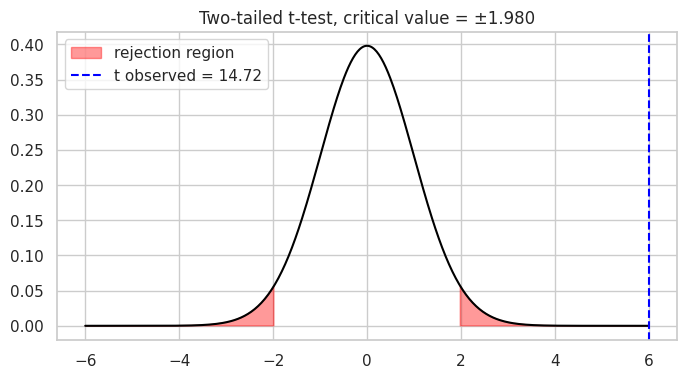

In [13]:
df_t = len(male) + len(female) - 2
t_crit = stats.t.ppf(1 - alpha / 2, df_t)
xs = np.linspace(-6, 6, 500)
t_obs, _ = stats.ttest_ind(male, female)
plt.figure(figsize=(8, 4))
plt.plot(xs, stats.t(df_t).pdf(xs), color="black")
plt.fill_between(xs, stats.t(df_t).pdf(xs), where=(xs <= -t_crit) | (xs >= t_crit), color="red", alpha=0.4, label="rejection region")
plt.axvline(t_obs if abs(t_obs) < 6 else 6, color="blue", linestyle="--", label=f"t observed = {t_obs:.2f}")
plt.title(f"Two-tailed t-test, critical value = ±{t_crit:.3f}")
plt.legend()
plt.show()

## Type I error, Type II error and power

Empirical Type I error rate (H0 true): 0.0466


Empirical power (d = 0.5, n = 30): 0.4788
Empirical Type II error (beta): 0.5212
Theoretical power: 0.4779
Sample size per group for 80% power: 64


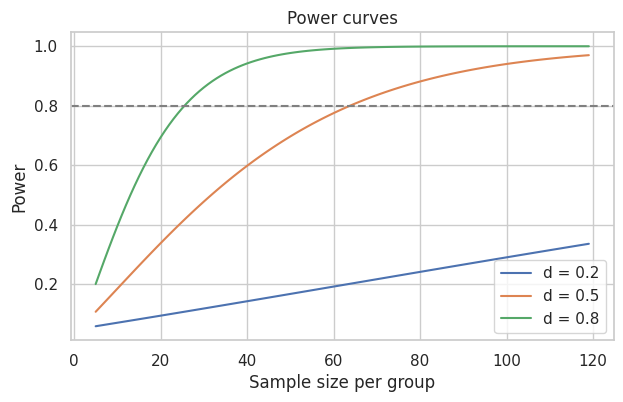

In [14]:
n_sim, n = 5000, 30
rejections = 0
for _ in range(n_sim):
    a = rng.normal(0, 1, n)
    b = rng.normal(0, 1, n)
    if stats.ttest_ind(a, b).pvalue < alpha:
        rejections += 1
print("Empirical Type I error rate (H0 true):", rejections / n_sim)

effect = 0.5
rejections = 0
for _ in range(n_sim):
    a = rng.normal(0, 1, n)
    b = rng.normal(effect, 1, n)
    if stats.ttest_ind(a, b).pvalue < alpha:
        rejections += 1
power_sim = rejections / n_sim
print("Empirical power (d = 0.5, n = 30):", power_sim)
print("Empirical Type II error (beta):", 1 - power_sim)
analysis = TTestIndPower()
print("Theoretical power:", round(analysis.power(effect_size=effect, nobs1=n, alpha=alpha), 4))
print("Sample size per group for 80% power:", int(np.ceil(analysis.solve_power(effect_size=effect, power=0.8, alpha=alpha))))

sizes = np.arange(5, 120)
plt.figure(figsize=(7, 4))
for d in [0.2, 0.5, 0.8]:
    plt.plot(sizes, [analysis.power(effect_size=d, nobs1=s, alpha=alpha) for s in sizes], label=f"d = {d}")
plt.axhline(0.8, color="gray", linestyle="--")
plt.xlabel("Sample size per group"); plt.ylabel("Power"); plt.legend()
plt.title("Power curves")
plt.show()

## Summary of all tests

In [15]:
summary = pd.DataFrame(results, columns=["test", "statistic", "p_value"])
summary["decision (alpha=0.05)"] = np.where(summary["p_value"] < alpha, "Reject H0", "Fail to reject H0")
summary.round(6)

,test,statistic,p_value,decision (alpha=0.05)
0,One-sample t-test,0.190347,0.849304,Fail to reject H0
1,One-sample z-test,-0.375593,0.707220,Fail to reject H0
2,Two-sample t-test (Gentoo male vs female mass),14.721676,0.000000,Reject H0
3,One-tailed t-test (male > female),14.721676,0.000000,Reject H0
4,Paired t-test,5.879079,0.000002,Reject H0
5,F-test (variance Adelie vs Gentoo mass),0.836384,0.305121,Fail to reject H0
6,One-proportion z-test,-0.606349,0.544283,Fail to reject H0
7,Two-proportion z-test,0.043987,0.964915,Fail to reject H0
8,Chi-square independence (day vs time),217.112673,0.000000,Reject H0
9,Chi-square goodness of fit (days uniform),43.704918,0.000000,Reject H0
